# 뱀서라이크 게임 밸런스 분석: 자동 플레이 로그로 본 수정 전후 비교

직접 만든 Unity 게임에 **플레이 로그 기록 기능**과 **FSM 기반 자동 플레이 봇**을 붙여 데이터를 모으고,
그 데이터로 밸런스 문제를 찾아 고친 뒤 **같은 조건으로 다시 측정**해 효과를 검증한 분석입니다.

| 단계 | 내용 |
|---|---|
| 데이터 수집 | `GameLogger.cs`가 판마다 CSV 3개(runs / events / snapshots)를 저장 |
| 플레이 | `AutoPlayer.cs` 봇이 캐릭터 2종 × 아이템 전략 3종을 돌아가며 30판씩 플레이 (8배속) |
| 비교 | **v1** 원본 밸런스 vs **v2** 수정 밸런스 (스폰 단계 2→5개, 경험치 곡선 완화) |

### 실행 방법
1. 필요한 패키지 설치: `pip install pandas matplotlib scipy jupyter`
2. 이 노트북이 있는 `Analysis` 폴더에서 `jupyter notebook` 실행
3. 위에서부터 셀을 하나씩 `Shift + Enter`로 실행

### 폴더 구조
```
Analysis/
├── balance_analysis.ipynb      ← 이 노트북
├── data/
│   ├── PlayLogs_v1_bot_before/  ← 수정 전 봇 30판
│   └── PlayLogs_v2_bot_after/   ← 수정 후 봇 30판
└── figures/                     ← 실행하면 그래프 이미지가 저장됨
```

## 0. 준비: 라이브러리와 한글 폰트 설정
- **pandas**: 표 형태의 데이터를 다루는 라이브러리 (엑셀을 코드로 다룬다고 생각하면 됨)
- **matplotlib**: 그래프 그리기
- **sqlite3**: 파이썬에 기본 내장된 SQL 데이터베이스 (3장에서 SQL로 같은 분석을 해봄)
- **scipy**: 통계 검정

matplotlib는 기본 폰트에 한글이 없어서 그래프의 한글이 깨지므로, 운영체제에 맞는 한글 폰트를 지정합니다.

In [1]:
import os
import platform
import sqlite3

import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 한글 폰트 설정 (Windows: 맑은 고딕, Mac: 애플고딕, 그 외: Noto Sans CJK)
system = platform.system()
if system == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif system == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
else:
    plt.rcParams["font.family"] = "Noto Sans CJK JP"
plt.rcParams["axes.unicode_minus"] = False   # 음수 기호 깨짐 방지
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", 30)
os.makedirs("figures", exist_ok=True)

COLORS = {"v1": "#9aa5b1", "v2": "#2f6fdf"}   # 그래프에서 버전별 색
print("준비 완료")

준비 완료


## 1. 데이터 불러오기

게임은 판이 끝날 때마다 CSV 파일 3개에 한 줄씩(또는 여러 줄씩) 덧붙여 저장합니다.

| 파일 | 한 행의 의미 | 주요 열 |
|---|---|---|
| `runs.csv` | 한 판 | 캐릭터, 승패, 생존 시간, 최종 레벨, 처치 수, 봇 전략, 밸런스 버전 |
| `events.csv` | 이벤트 1건 | 레벨업 / 아이템 선택 / 처치 / 사망, 발생 시각 |
| `snapshots.csv` | 5초마다의 상태 | 레벨, 처치 수, 체력, 화면에 살아있는 적 수 |

버전 폴더마다 같은 이름의 파일이 있으므로, 폴더를 읽는 함수를 하나 만들고 `ver` 열을 붙여 하나로 합칩니다.

In [2]:
DATA_DIR = "data"
VERSIONS = {
    "v1": "PlayLogs_v1_bot_before",
    "v2": "PlayLogs_v2_bot_after",
}

def load_version(ver, folder):
    path = os.path.join(DATA_DIR, folder)
    # 게임이 BOM 포함 UTF-8로 저장하므로 encoding="utf-8-sig"
    runs = pd.read_csv(os.path.join(path, "runs.csv"), encoding="utf-8-sig")
    events = pd.read_csv(os.path.join(path, "events.csv"), encoding="utf-8-sig")
    snaps = pd.read_csv(os.path.join(path, "snapshots.csv"), encoding="utf-8-sig")
    for df in (runs, events, snaps):
        df["ver"] = ver
    return runs, events, snaps

loaded = [load_version(v, f) for v, f in VERSIONS.items()]
runs = pd.concat([x[0] for x in loaded], ignore_index=True)
events = pd.concat([x[1] for x in loaded], ignore_index=True)
snaps = pd.concat([x[2] for x in loaded], ignore_index=True)

# 분석에 자주 쓰는 열 추가
runs["win"] = (runs["result"] == "win").astype(int)          # 승리=1, 패배=0
runs["character"] = runs["character_id"].map({0: "쌀농부(삽 시작)", 1: "보리농부(엽총 시작)"})

print("runs:", runs.shape, " events:", events.shape, " snapshots:", snaps.shape)
runs.head()

runs: (60, 20)  events: (50879, 10)  snapshots: (2899, 7)


,run_id,started_at,character_id,result,survival_time,max_game_time,final_level,total_kills,final_health,max_health,controller,item_strategy,sim_speed,bot_wander_time,bot_kite_time,bot_flee_time,ver,balance_version,win,character
0,20261104_112752_191,2026-11-04 11:27:52,0,win,300.000,300,123,1209,100.0,100,bot,Random,8,6.309,243.412,50.278,v1,NaN,1,쌀농부(삽 시작)
1,20261104_112831_289,2026-11-04 11:28:31,1,lose,41.377,300,3,8,0.0,100,bot,Random,8,7.960,7.712,25.765,v1,NaN,0,보리농부(엽총 시작)
2,20261104_112838_034,2026-11-04 11:28:38,0,win,300.000,300,128,1258,100.0,100,bot,WeaponFirst,8,8.013,291.094,7.722,v1,NaN,1,쌀농부(삽 시작)
3,20261104_112918_006,2026-11-04 11:29:18,1,win,300.000,300,130,1263,100.0,100,bot,WeaponFirst,8,14.201,291.830,1.388,v1,NaN,1,보리농부(엽총 시작)
4,20261104_112958_077,2026-11-04 11:29:58,0,win,300.000,300,128,1253,100.0,100,bot,GearFirst,8,4.759,267.950,34.163,v1,NaN,1,쌀농부(삽 시작)


### 데이터 점검
분석 전에 **데이터가 의도대로 쌓였는지** 확인합니다. 버전별 판 수, 조합(캐릭터 × 전략)이 고르게 나왔는지, 이벤트 종류별 건수를 봅니다.

In [3]:
# 버전 x 캐릭터 x 전략별 판 수 → 모든 조합이 5판씩이면 정상
pd.crosstab([runs["ver"], runs["character"]], runs["item_strategy"])

item_strategy    GearFirst  Random  WeaponFirst
ver character                                  
v1  보리농부(엽총 시작)          5       5            5
    쌀농부(삽 시작)            5       5            5
v2  보리농부(엽총 시작)          5       5            5
    쌀농부(삽 시작)            5       5            5

In [4]:
events.groupby(["ver", "event_type"]).size().unstack()

event_type,death,item_pick,kill,level_up
ver,,,,
v1,10,2614,24799,2584
v2,7,503,19889,473


## 2. 수정 전(v1) 분석: 무엇이 문제였나

### 2-1. 승률
`win` 열은 승리=1, 패배=0이므로 **평균을 내면 곧 승률**입니다.

In [5]:
v1 = runs[runs["ver"] == "v1"]
print(f"v1 전체 승률: {v1['win'].mean():.0%}  ({v1['win'].sum()}승 / {len(v1)}판)")

# 캐릭터 x 전략별 승률 (pivot_table: 엑셀의 피벗 테이블과 같은 기능)
v1.pivot_table(index="character", columns="item_strategy", values="win", aggfunc="mean").round(2)

v1 전체 승률: 67%  (20승 / 30판)


item_strategy,GearFirst,Random,WeaponFirst
character,,,
보리농부(엽총 시작),0.0,0.2,1.0
쌀농부(삽 시작),1.0,0.8,1.0


### 2-2. 언제 죽었나: "1분의 벽"
패배한 판의 생존 시간을 보면, 모두 **1분 안팎에 몰려 있습니다.** 1분을 넘긴 판은 전부 승리했습니다.

count    10.0
mean     41.6
std       9.0
min      30.8
25%      35.6
50%      40.8
75%      45.7
max      61.6
Name: survival_time, dtype: float64

60초를 넘긴 판의 승률: 100%


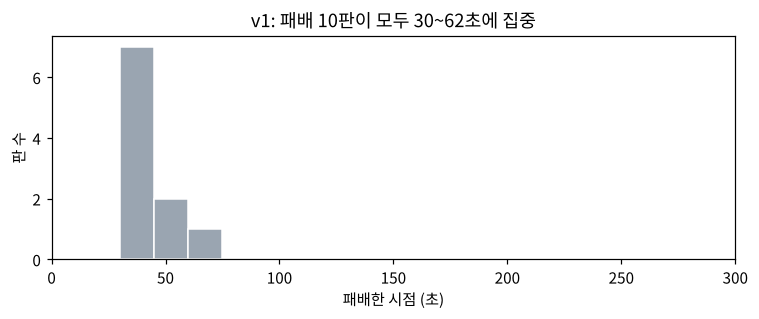

In [6]:
v1_lose = v1[v1["win"] == 0]
print(v1_lose["survival_time"].describe().round(1))
print("\n60초를 넘긴 판의 승률:", f"{v1[v1['survival_time'] > 62]['win'].mean():.0%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(v1_lose["survival_time"], bins=range(0, 301, 15), color=COLORS["v1"], edgecolor="white")
ax.set_xlim(0, 300)
ax.set_xlabel("패배한 시점 (초)")
ax.set_ylabel("판 수")
ax.set_title("v1: 패배 10판이 모두 30~62초에 집중")
plt.tight_layout()
plt.savefig("figures/v1_death_time.png")
plt.show()

### 2-3. 생존을 가른 요인: 15초 안에 삽을 얻었나
v1은 10초에 적의 스폰 빈도·체력·속도가 한꺼번에 오릅니다. 이 급경사를 버티는 데 **회전형 근접무기 '삽'**이 결정적이었는지 확인합니다.

1. `events`에서 아이템 선택(`item_pick`) 중 삽(`detail_id == 0`)을 처음 얻은(`value == 1`) 시각을 판별로 구하고
2. `runs`에 붙인 뒤(`map`)
3. "15초 안에 얻었나"와 "승패"를 교차표로 봅니다.

In [7]:
picks = events[events["event_type"] == "item_pick"]
shovel_time = (picks[(picks["detail_id"] == 0) & (picks["value"] == 1)]
               .groupby("run_id")["game_time"].min())

v1 = v1.copy()
v1["shovel_time"] = v1["run_id"].map(shovel_time)      # 끝까지 못 얻으면 NaN
v1["shovel_by_15s"] = v1["shovel_time"] <= 15           # NaN <= 15 는 False

pd.crosstab(v1["shovel_by_15s"], v1["result"], margins=True)

result,lose,win,All
shovel_by_15s,,,
False,9,0,9
True,1,20,21
All,10,20,30


**→ 15초 안에 삽이 있으면 21판 중 20판 승리, 없으면 9판 모두 패배.**
엽총으로 시작하는 보리농부는 레벨업 때 운 좋게 삽이 나와야만 살아남는 구조였습니다.

### 2-4. 성장 속도와 아이템 선택
이긴 판의 최종 레벨과, 아이템 선택 중 **음료수(회복, `detail_id == 4`)** 비율을 봅니다.
음료수는 무기·장비가 만렙이 되면 대신 나오는 아이템이라, 이 비율이 높을수록 "고를 게 없는" 상태가 길었다는 뜻입니다.

In [8]:
v1_win_ids = v1.loc[v1["win"] == 1, "run_id"]
v1_picks = picks[picks["run_id"].isin(v1_win_ids)]

print(f"이긴 판 평균 레벨: {v1.loc[v1['win'] == 1, 'final_level'].mean():.1f}")
print(f"아이템 선택 중 음료수 비율: {(v1_picks['detail_id'] == 4).mean():.0%}")

이긴 판 평균 레벨: 127.5
아이템 선택 중 음료수 비율: 84%


## 3. 같은 분석을 SQL로

pandas로 한 분석을 **SQL로도** 해봅니다. 실무에서는 데이터가 DB에 있는 경우가 많아서 SQL로 바로 뽑을 수 있어야 합니다.
파이썬에 내장된 `sqlite3`로 메모리에 임시 DB를 만들고, DataFrame을 테이블로 넣습니다(`to_sql`).

In [9]:
conn = sqlite3.connect(":memory:")
runs.to_sql("runs", conn, index=False)
events.to_sql("events", conn, index=False)
snaps.to_sql("snapshots", conn, index=False)

def sql(query):
    return pd.read_sql_query(query, conn)

print("테이블 생성 완료:", sql("SELECT name FROM sqlite_master WHERE type='table'")["name"].tolist())

테이블 생성 완료: ['runs', 'events', 'snapshots']


### 3-1. 버전 · 캐릭터별 승률 (GROUP BY, CASE)

In [10]:
sql('''
SELECT ver,
       character_id,
       COUNT(*)                                              AS runs,
       SUM(CASE WHEN result = 'win' THEN 1 ELSE 0 END)       AS wins,
       ROUND(AVG(CASE WHEN result = 'win' THEN 1.0 ELSE 0 END), 2) AS win_rate
FROM runs
GROUP BY ver, character_id
ORDER BY ver, character_id
''')

,ver,character_id,runs,wins,win_rate
0,v1,0,15,14,0.93
1,v1,1,15,6,0.40
2,v2,0,15,11,0.73
3,v2,1,15,12,0.80


### 3-2. 삽 획득 시점과 승패 (WITH, LEFT JOIN)
`WITH`로 "판별 삽 첫 획득 시각" 임시 테이블을 만들고 `runs`에 `LEFT JOIN` 합니다.
삽을 끝까지 못 얻은 판도 빠지지 않게 하려고 `INNER JOIN`이 아니라 `LEFT JOIN`을 씁니다.

In [11]:
sql('''
WITH shovel AS (
    SELECT run_id, MIN(game_time) AS first_shovel
    FROM events
    WHERE event_type = 'item_pick' AND detail_id = 0 AND value = 1
    GROUP BY run_id
)
SELECT r.ver,
       CASE WHEN s.first_shovel <= 15 THEN '15초 안에 획득' ELSE '15초까지 없음' END AS shovel_group,
       COUNT(*)                                        AS runs,
       SUM(CASE WHEN r.result = 'win' THEN 1 ELSE 0 END) AS wins
FROM runs r
LEFT JOIN shovel s ON r.run_id = s.run_id
GROUP BY r.ver, shovel_group
ORDER BY r.ver, shovel_group
''')

,ver,shovel_group,runs,wins
0,v1,15초 안에 획득,21,20
1,v1,15초까지 없음,9,0
2,v2,15초 안에 획득,18,14
3,v2,15초까지 없음,12,9


v1에서는 삽 유무가 승패를 거의 완벽하게 갈랐지만, **v2에서는 삽 없이도 이기는 판이 생겼습니다.** 초반 급경사가 사라졌기 때문입니다.

## 4. 수정 전후 비교 (v1 vs v2)

### 무엇을 바꿨나
| 항목 | v1 (원본) | v2 (수정) |
|---|---|---|
| 스폰 단계 | 2단계, **10초**에 한 번 상승 | 5단계, **60초**마다 상승 |
| 필요 경험치 | 1, 2, 3, …, 10 (이후 10 고정) | 3, 5, 8, 12, …, 80 (점점 증가) |

봇, 판 수(30), 배속(8배), 캐릭터·전략 조합은 **똑같이** 유지했습니다. 따라서 차이는 밸런스 변경의 효과로 볼 수 있습니다.

### 4-1. 핵심 지표 한눈에 보기

In [12]:
def summarize(ver):
    r = runs[runs["ver"] == ver]
    wins = r[r["win"] == 1]
    p = picks[picks["run_id"].isin(wins["run_id"])]    # 이긴 판의 아이템 선택만
    lu = events[(events["ver"] == ver) & (events["event_type"] == "level_up")]
    lu_win = lu[lu["run_id"].isin(wins["run_id"])]
    return {
        "승률": f"{r['win'].mean():.0%}",
        "패배 시점 범위(초)": f"{r.loc[r['win'] == 0, 'survival_time'].min():.0f} ~ {r.loc[r['win'] == 0, 'survival_time'].max():.0f}",
        "패배 시점 중앙값(초)": round(r.loc[r["win"] == 0, "survival_time"].median(), 1),
        "이긴 판 평균 레벨": f"{wins['final_level'].mean():.1f}",
        "이긴 판 분당 레벨업": round(len(lu_win) / len(wins) / 5, 1),
        "음료수 선택 비율(이긴 판)": f"{(p['detail_id'] == 4).mean():.0%}",
        "보리농부 승률": f"{r.loc[r['character_id'] == 1, 'win'].mean():.0%}",
    }

summary = pd.DataFrame({v: summarize(v) for v in VERSIONS})
summary

,v1,v2
승률,67%,77%
패배 시점 범위(초),31 ~ 62,86 ~ 225
패배 시점 중앙값(초),40.8,120.6
이긴 판 평균 레벨,127.5,18.7
이긴 판 분당 레벨업,25.5,3.7
음료수 선택 비율(이긴 판),84%,25%
보리농부 승률,40%,80%


### 4-2. 난이도 곡선: 시간에 따라 화면에 적이 얼마나 있나
이긴 판만 골라 30초 구간별로 **화면에 살아있는 적 수**의 평균을 그립니다.
- v1: 60초에 정점을 찍고 **오히려 줄어듭니다.** 플레이어가 너무 빨리 강해져서 후반이 쉬워지는 구조
- v2: 5분 내내 **꾸준히 증가**합니다. 의도한 "점점 어려워지는 게임"

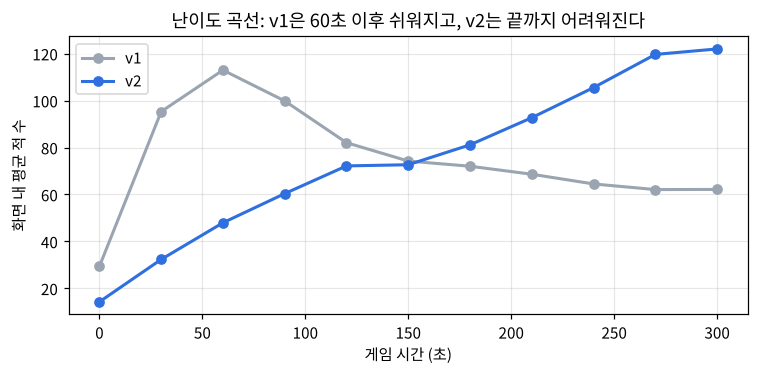

bucket,0,30,60,90,120,150,180,210,240,270,300
ver,,,,,,,,,,,
v1,29.0,95.0,113.0,100.0,82.0,74.0,72.0,69.0,64.0,62.0,62.0
v2,14.0,32.0,48.0,60.0,72.0,73.0,81.0,93.0,106.0,120.0,122.0


In [13]:
win_ids = runs.loc[runs["win"] == 1, "run_id"]
s = snaps[snaps["run_id"].isin(win_ids)].copy()
s["bucket"] = (s["game_time"] // 30 * 30).astype(int)      # 0, 30, 60, ... 초 구간
curve = s.pivot_table(index="bucket", columns="ver", values="active_enemies", aggfunc="mean")

fig, ax = plt.subplots(figsize=(7, 3.5))
for ver in curve.columns:
    ax.plot(curve.index, curve[ver], marker="o", color=COLORS[ver], label=ver, linewidth=2)
ax.set_xlabel("게임 시간 (초)")
ax.set_ylabel("화면 내 평균 적 수")
ax.set_title("난이도 곡선: v1은 60초 이후 쉬워지고, v2는 끝까지 어려워진다")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/difficulty_curve.png")
plt.show()
curve.round(0).T

### 4-3. 레벨 성장 곡선
5초마다 기록한 레벨을 이긴 판끼리 평균 냅니다.

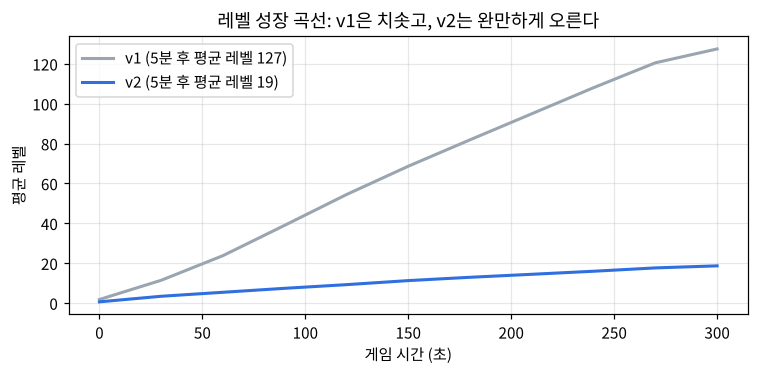

In [14]:
lv = s.pivot_table(index="bucket", columns="ver", values="level", aggfunc="mean")

# 같은 축에 그려야 차이의 크기가 제대로 보임
fig, ax = plt.subplots(figsize=(7, 3.5))
for ver in lv.columns:
    ax.plot(lv.index, lv[ver], color=COLORS[ver], linewidth=2,
            label=f"{ver} (5분 후 평균 레벨 {lv[ver].iloc[-1]:.0f})")
ax.set_xlabel("게임 시간 (초)")
ax.set_ylabel("평균 레벨")
ax.set_title("레벨 성장 곡선: v1은 치솟고, v2는 완만하게 오른다")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/level_curve.png")
plt.show()

### 4-4. 아이템 전략별 승률: 새로 생긴 문제
v2에서는 성장이 느려진 만큼 **무엇을 고르느냐가 중요해졌습니다.** 그 결과 장비 우선(GearFirst) 전략이 크게 불리해졌습니다.
무기 없이 장갑·신발에 투자하면 버티지 못한다는 뜻으로, **장비가 무기에 비해 약하다**는 다음 개선 과제가 드러났습니다.

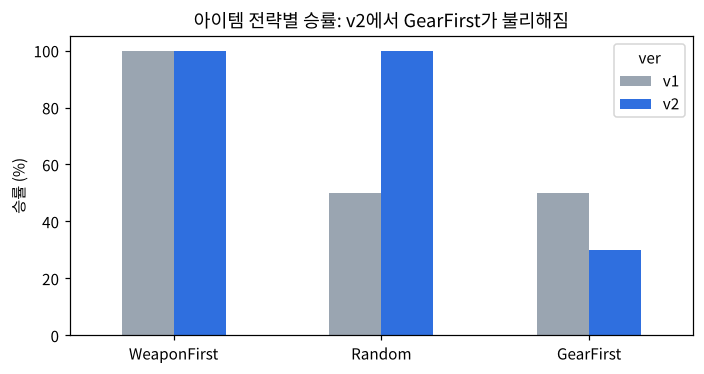

ver,v1,v2
item_strategy,,
WeaponFirst,1.0,1.0
Random,0.5,1.0
GearFirst,0.5,0.3


In [15]:
strat = runs.pivot_table(index="item_strategy", columns="ver", values="win", aggfunc="mean")
strat = strat.loc[["WeaponFirst", "Random", "GearFirst"]]

ax = (strat * 100).plot(kind="bar", color=[COLORS["v1"], COLORS["v2"]], figsize=(6.5, 3.5), rot=0)
ax.set_ylabel("승률 (%)")
ax.set_xlabel("")
ax.set_ylim(0, 105)
ax.set_title("아이템 전략별 승률: v2에서 GearFirst가 불리해짐")
plt.tight_layout()
plt.savefig("figures/strategy_win_rate.png")
plt.show()
strat.round(2)

## 5. 차이가 우연은 아닐까: 통계적 검정

숫자가 달라졌다고 바로 "개선됐다"고 말하면 안 됩니다. 판 수가 적으면 **우연히** 차이가 날 수 있기 때문입니다.

### 5-1. 승률 67% → 77%: 피셔의 정확 검정
표본이 작은 2×2 표(버전 × 승패)에 쓰는 검정입니다. **p-value가 0.05보다 크면** "우연으로도 충분히 나올 수 있는 차이"로 봅니다.

In [16]:
table = pd.crosstab(runs["ver"], runs["result"])[["win", "lose"]]
odds, p = stats.fisher_exact(table.values)
print(table, "\n")
print(f"p-value = {p:.3f}  →  {'의미 있는 차이' if p < 0.05 else '통계적으로 의미 있는 차이라고 보기 어려움'}")

result  win  lose
ver              
v1       20    10
v2       23     7 

p-value = 0.567  →  통계적으로 의미 있는 차이라고 보기 어려움


**→ 승률 차이는 30판씩으로는 확신할 수 없습니다.** 그래서 이번 개선의 근거는 승률이 아니라 아래처럼 차이가 압도적인 지표로 잡습니다.

### 5-2. 패배 시점: 맨-휘트니 U 검정
두 그룹의 값이 어느 쪽이 더 큰 경향인지 보는 검정입니다(정규분포를 가정하지 않아 표본이 작을 때 적합).

In [17]:
lose_v1 = runs.loc[(runs["ver"] == "v1") & (runs["win"] == 0), "survival_time"]
lose_v2 = runs.loc[(runs["ver"] == "v2") & (runs["win"] == 0), "survival_time"]
u, p = stats.mannwhitneyu(lose_v1, lose_v2, alternative="two-sided")
print(f"패배 시점 중앙값: v1 {lose_v1.median():.0f}초 → v2 {lose_v2.median():.0f}초")
print(f"p-value = {p:.4f}  →  {'의미 있는 차이' if p < 0.05 else '의미 있는 차이라고 보기 어려움'}")

패배 시점 중앙값: v1 41초 → v2 121초
p-value = 0.0001  →  의미 있는 차이


### 5-3. 이긴 판의 최종 레벨

In [18]:
lv1 = runs.loc[(runs["ver"] == "v1") & (runs["win"] == 1), "final_level"]
lv2 = runs.loc[(runs["ver"] == "v2") & (runs["win"] == 1), "final_level"]
u, p = stats.mannwhitneyu(lv1, lv2, alternative="two-sided")
print(f"이긴 판 평균 레벨: v1 {lv1.mean():.1f} → v2 {lv2.mean():.1f}")
print(f"p-value = {p:.2e}  →  {'의미 있는 차이' if p < 0.05 else '의미 있는 차이라고 보기 어려움'}")

이긴 판 평균 레벨: v1 127.5 → v2 18.7
p-value = 1.69e-08  →  의미 있는 차이


## 6. 결론

### 발견한 문제 (v1)
1. **1분의 벽**: 10초에 난이도가 한꺼번에 오르고 그 뒤로는 멈춤 → 패배가 전부 1분 안팎, 1분을 넘기면 100% 승리
2. **과도한 성장**: 5분에 레벨 약 130, 분당 25~30번 레벨업, 아이템 선택의 84%가 음료수
3. **무기 의존**: 15초 안에 삽이 없으면 9판 모두 패배 → 엽총으로 시작하는 캐릭터가 크게 불리

### 수정 효과 (v2)
- 패배 시점이 1분대에서 **1~4분대로 분산** (통계적으로 유의)
- 최종 레벨 127 → **약 19**, 음료수 비율 84% → **25%** → 아이템 선택에 다시 의미가 생김
- 난이도 곡선이 **5분 내내 상승**하는 형태로 바뀜
- 보리농부 승률 40% → **80%**

### 한계
- 판 수가 버전당 30판(조합당 5판)이라 **승률 차이는 통계적으로 확신할 수 없음**
- 사람이 아닌 **봇 기준** 결과이며, 봇의 실력(반응 속도, 판단 규칙)에 따라 결과가 달라질 수 있음
- v2의 값은 1차 가설이라 최적값이라고 볼 수 없음

### 다음 단계
- **v3**: 장비(장갑·신발) 효과를 강화해 GearFirst 전략의 승률을 끌어올리고, 무기·장비가 후반에 만렙이 되도록 경험치 곡선 미세 조정
- 판 수를 늘려 승률 차이를 통계적으로 검증